# Breast Cancer Detection  -  Project 1

**Machine Learning Foundations | CAI2100C**  
**Student researcher:** Juan Luna Santibanez  
**Assignment:** Breast Cancer supervised classification, using the instructor-provided CSV and worksheet.  
**Grading scope:** Six original course stages, three required algorithms, completed code, executed outputs and a reasoned best-model decision.

**Scientific boundary:** The dataset classes are **B (benign)** and **M (malignant)**, not the invasive/non-invasive categories suggested by the scenario. This analysis is **educational only**. It is not a medical diagnostic device.

**Project format:** Individual project completed by Juan Luna Santibanez with Professor Beth Muturi's approval.

# The Scenario
“About 1 in 8 U.S. women (about 13%) will develop invasive breast cancer over the course of her lifetime. <br>
In 2021, an estimated 281,550 new cases of invasive breast cancer are expected to be diagnosed in women in the U.S., along with 49,290 new cases of non-invasive (in situ) breast cancer.”<br>

A timely response is crucial so that real invasive cases are treated promptly, while we do not put those in non-invasive cases under unnecessary tests or procedures.<br>
However, there is a crunch on professionals to check on the reports.<br>
Is there a way to overcome this problem?<br>

Source: U.S. Breast Cancer Statistics. BreastCancer Org. https://www.breastcancer.org/symptoms/understand_bc/statistics 

# Tips for working on this project
You will be using these two concepts to be able to successfully complete this project:
1. Supervised Learning models
2. AI Project Cycle <br>

If needed, please revise your notes on these topics.

# Section 1: Understand the Problem

One of the key points of solving an AI problem is to understand the problem statement correctly. <br>
You need to understand what is the correct problems that you are solving.<br>
You want to solve the root problem and not the symptoms.<br>
To do that, you can use tools like 5 Whys, decomposition, and Fish-bone diagram.<br>
You can then write your problem statement.<br>
It may include helpful information, like who is affected, what is the problem, where is it happening, and when does it happen.<br>
need more details to each.<br>

Based on the scenario above, write your problem statement in the cell below!<br>

In [1]:
# I want to understand whether numerical measurements of cell nuclei can help distinguish
# benign (B) from malignant (M) breast mass samples in the dataset supplied for this class.
# The central problem is classifying a sample from its measured features while limiting
# incorrect predictions, particularly missed malignant cases (false negatives).
# I will compare three supervised learning algorithms: KNN, SVM, and Decision Tree.
# I will evaluate them on held-out observations instead of assuming training accuracy is enough.
# My result is an educational classification experiment, not a medical diagnosis.

# Section 2: Data Acquisition

Data is the main ingredient for AI model. <br>
Where can you find your data? <br>
Write your answer in the cell below. <br>

In this scenario, you are given a CSV file with the info.<br>
In the cell below, write down which column will serve as a target for your AI model?

In [2]:
# The primary data source is the CSV distributed with Project 1 Dependencies in Canvas.
# I will use that exact course file rather than silently substituting an online dataset.
# Each row is one labeled sample, and the diagnosis column is the target I want to predict.
# The original classes are B = benign and M = malignant.
# The numeric measurements are input features; the 'id' column is an identifier, not a
# clinical measurement. I keep it in the classroom baseline to match the template's 31
# columns, then examine removing it in my separate optional research notebook.

# Import libraries and insert the file

In [3]:
# I import data-handling libraries to read, check, and transform the supplied CSV.
import pandas as pd
import numpy as np

# I import plotting libraries to display class balance, correlations, and error counts.
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap  # Included in the original template; not required here.

# I import preprocessing, data splitting, and the evaluation metrics used in class.
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Model 1: KNN classifies samples using nearby training observations.
from sklearn.neighbors import KNeighborsClassifier

# Model 2: SVC is the classification implementation of a Support Vector Machine.
from sklearn.svm import SVC

# Model 3: Decision Tree classifies samples through learned conditional splits.
from sklearn.tree import DecisionTreeClassifier

# I fix the random state so that the same input produces the same split and results.
SEED = 42

# I keep the original CSV filename so the instructor's data contract remains unchanged.
# The original MDC dataset is preferred in every environment.
# In Colab, the identical data file can be downloaded from my public repository.
# If external access is unavailable, the provided course CSV can be uploaded manually.
from pathlib import Path
from glob import glob
import hashlib
import urllib.request

DATA_PATH = Path('[Dataset]_BreastCancer.csv')
if not DATA_PATH.is_file():
    locations = [
        Path('data/[Dataset]_BreastCancer.csv'),
        Path('../data/[Dataset]_BreastCancer.csv'),
        Path('/content/[Dataset]_BreastCancer.csv'),
    ]
    locations.extend(Path(p) for p in glob('/kaggle/input/**/[Dataset]_BreastCancer.csv', recursive=True))
    source = next((p for p in locations if p.is_file()), None)
    if source is not None:
        DATA_PATH = source
    else:
        url = 'https://raw.githubusercontent.com/SupaHumano/CAI2100C-Breast-Cancer-Classification/main/data/%5BDataset%5D_BreastCancer.csv'
        try:
            urllib.request.urlretrieve(url, str(DATA_PATH))
        except Exception as exc:
            if DATA_PATH.exists():
                DATA_PATH.unlink()
            try:
                from google.colab import files
                print('Please upload the original [Dataset]_BreastCancer.csv file from Project 1 Dependencies.')
                uploaded = files.upload()
                if DATA_PATH.name not in uploaded:
                    raise FileNotFoundError('The expected classroom dataset was not uploaded.')
            except ImportError:
                raise FileNotFoundError('Provide [Dataset]_BreastCancer.csv beside the notebook or in Kaggle input data.') from exc

actual_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_hash == 'ce1eb276766fa19f93eda0d63b3cdb3afbb07618ff1ab7f33f4135ef9075c664', 'The dataset differs from the instructor-provided file.'

# Load the original file and inspect its contents.
df = pd.read_csv(DATA_PATH)
assert {'id', 'diagnosis'}.issubset(df.columns), 'Unexpected column structure.'
print('Original dataset shape:', df.shape)
display(df.head())

Original dataset shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,NaN,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,NaN,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Section 3: Data Exploration

We need to clean the data.<br>
we want to make sure the data is clean.<br>
let's see how we can do it using this jupyter notebook<br>

## Any Missing Data?

In [4]:
# I count missing cells in the entire original dataset before modifying any records.
missing_by_column = df.isna().sum()
missing_total = int(missing_by_column.sum())
missing_rows = int(df.isna().any(axis=1).sum())
print('Missing cells:', missing_total)
print('Rows affected:', missing_rows)

# I inspect the individual columns so the cleanup decision is evidence-based.
print(missing_by_column.to_string())
print('Duplicate records:', int(df.duplicated().sum()))
assert missing_total == 28 and missing_rows == 26, 'The uploaded CSV differs from the audited class file.'

Missing cells: 28
Rows affected: 26
id                         0
diagnosis                  0
radius_mean                0
texture_mean               1
perimeter_mean             1
area_mean                  0
smoothness_mean            0
compactness_mean           1
concavity_mean             1
concave points_mean        1
symmetry_mean              0
fractal_dimension_mean     3
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              3
compactness_se             4
concavity_se               2
concave points_se          1
symmetry_se                3
fractal_dimension_se       0
radius_worst               1
texture_worst              3
perimeter_worst            0
area_worst                 2
smoothness_worst           1
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
Duplicate records: 0


## Fixing Missing Data
There are two methods we can try:<br>
1. remove missing data
2. fill missing data with a pre-set value <br>

In this exercise, we will be using the first method. <br>
If you want to use the second method, you will need to:
1. repeat the steps from the beginning
2. comment out the steps for method 1 so that you do not accidentally run it.

In [5]:
# Option 1  -  I follow the notebook's stated primary method and remove incomplete rows.
# The .copy() prevents later assignments from unintentionally modifying an old view.
rows_before = len(df)
df = df.dropna(axis=0).copy()
print('Rows before cleanup:', rows_before)
print('Rows removed:', rows_before - len(df))
print('Rows remaining:', len(df))
assert len(df) == 543 and not df.isna().any().any(), 'Missing-value cleanup failed.'
display(df.head())

Rows before cleanup: 569
Rows removed: 26
Rows remaining: 543


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.1578,0.08089,0.2087,0.07613,0.3345,0.8902,2.217,27.19,0.007510,0.03345,0.03672,0.01137,0.02165,0.005082,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440


In [6]:
# Option 2  -  an alternative approach, not run in the required baseline.
# I intentionally do NOT impute after using dropna(): doing both methods would change the
# question being tested. A separate, properly controlled imputation experiment would fit
# its imputer on training data only to avoid information leakage.
# Historical sample for a single feature, intentionally NOT executed:
# mean_value = df['texture_mean'].mean()
# df['texture_mean'] = df['texture_mean'].fillna(mean_value)
print('Option 2 was not executed; the main exercise uses Option 1 (dropna).')

Option 2 was not executed; the main exercise uses Option 1 (dropna).


## Rename the column for Target
Let's rename from diagnosis to target, for better clarity.

Class distribution after removing incomplete rows:
target
B    342
M    201


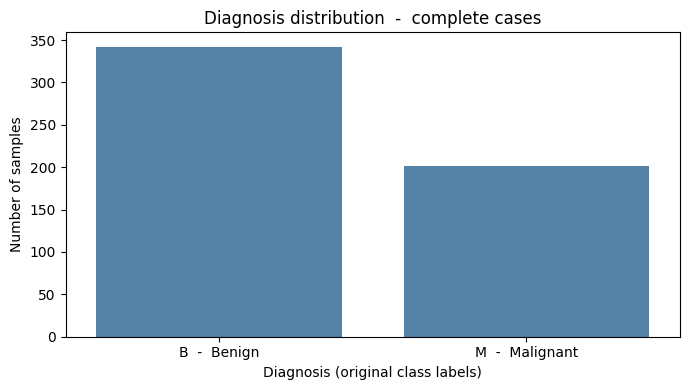

In [7]:
# I retain the instructor's target-column rename to make the labels explicit.
df = df.rename(columns={'diagnosis': 'target'})

# The source template says 'malicious' for M; the correct medical term is 'malignant'.
# I count the raw class labels before encoding them to numbers.
class_counts = df['target'].value_counts().reindex(['B', 'M'], fill_value=0)
print('Class distribution after removing incomplete rows:')
print(class_counts.to_string())

# I use a bar chart to make the imbalance visible, with readable labels.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='target', order=['B', 'M'], color='steelblue')
plt.xticks([0, 1], ['B  -  Benign', 'M  -  Malignant'])
plt.title('Diagnosis distribution  -  complete cases')
plt.xlabel('Diagnosis (original class labels)')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()
assert class_counts.to_dict() == {'B': 342, 'M': 201}

## Change the format for Target
In some of the models, the target need to be in numeric values.<br>
Therefore let's change the format from string to integer.

In [8]:
# I convert the class label to the numerical form required by the classifiers.
# Encoding malignant as 1 defines the clinically important positive class explicitly.
label_map = {'B': 0, 'M': 1}
assert set(df['target'].unique()) == set(label_map), 'Unexpected label in diagnosis column.'
df['target'] = df['target'].map(label_map).astype('int64')
print('Target coding: 0 = Benign, 1 = Malignant')
print(df['target'].value_counts().sort_index().to_string())
display(df.head())

Target coding: 0 = Benign, 1 = Malignant
target
0    342
1    201


,id,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,843786,1,12.45,15.70,82.57,477.1,0.12780,0.17000,0.1578,0.08089,0.2087,0.07613,0.3345,0.8902,2.217,27.19,0.007510,0.03345,0.03672,0.01137,0.02165,0.005082,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440


## Seeing the Correlation
In data exploration, it is important to see the correlation between the features.
Can you find the correlations for all the columns?

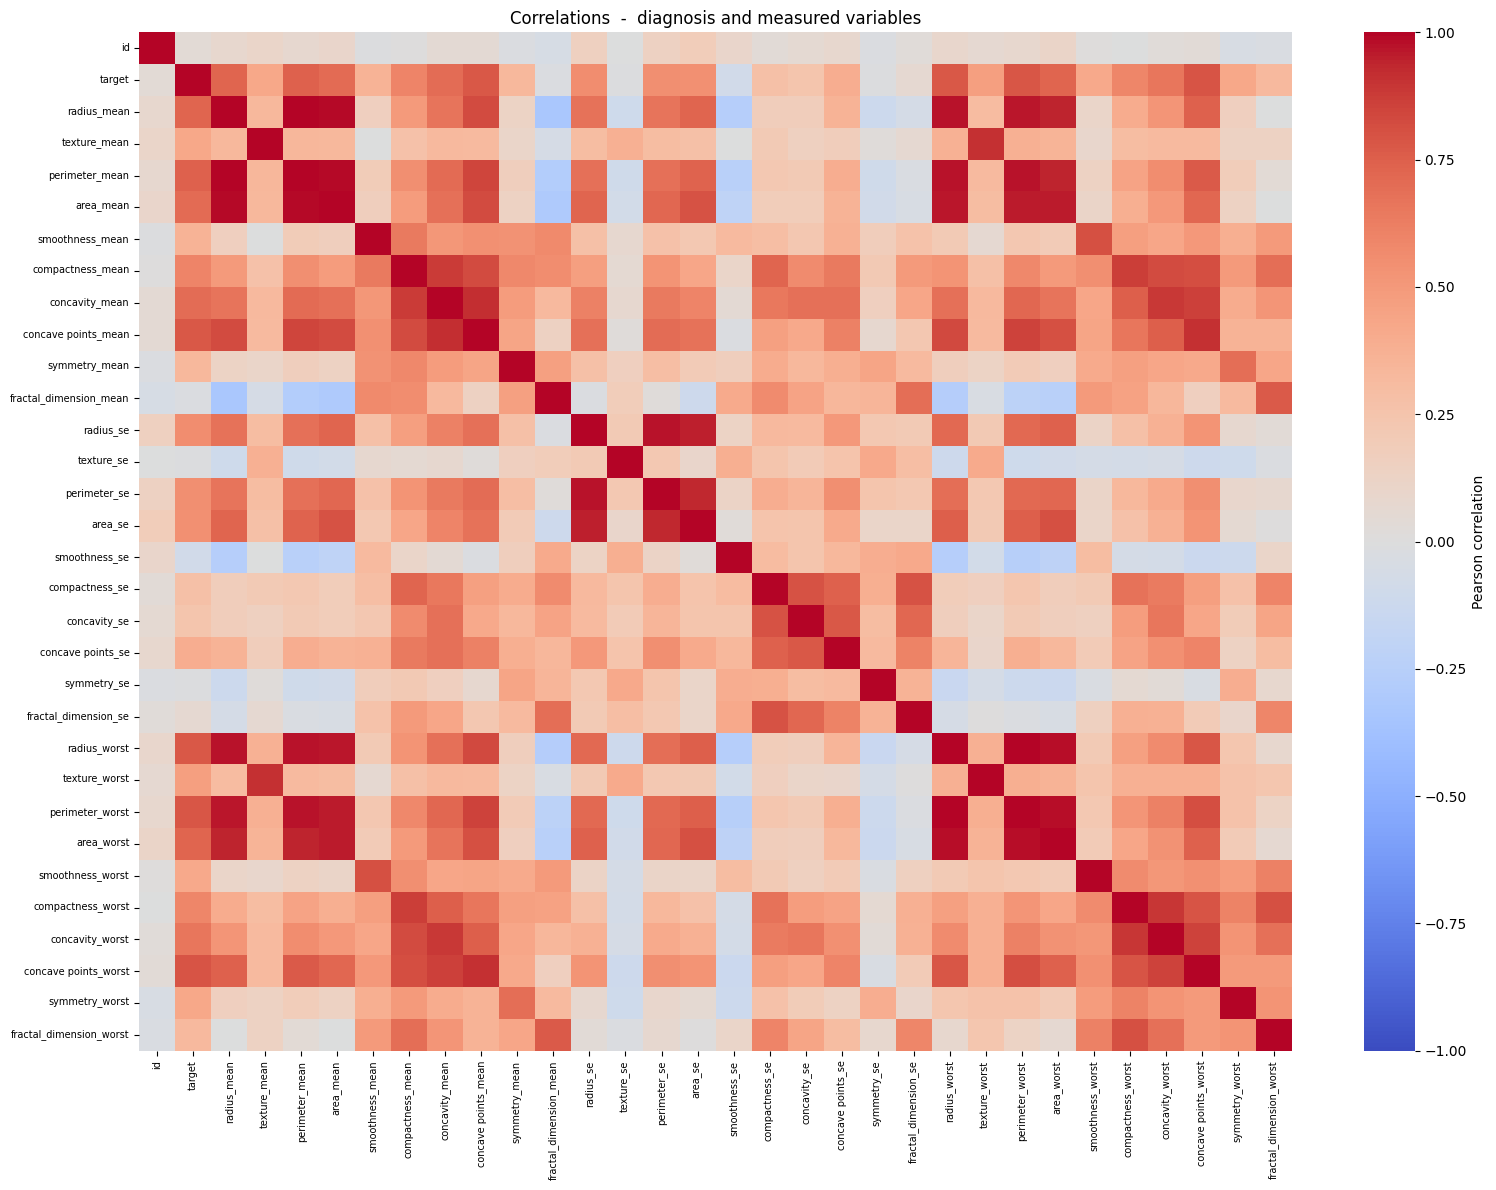

In [9]:
# I calculate Pearson correlations on the cleaned, numeric data.
# Correlation measures linear association, not causation or clinical importance.
corr = df.corr(numeric_only=True)

# I visualize the full matrix with a diverging palette centered at zero.
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=False, cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlations  -  diagnosis and measured variables')
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

## Finding the top features
The correlation map is too big. It is hard to extract useful information.<br>
Is there a way to filter out and find only those that are relevant for our target?

Features with absolute correlation to target above 0.75
concave points_worst    0.796219
perimeter_worst         0.783622
concave points_mean     0.780981
radius_worst            0.776534


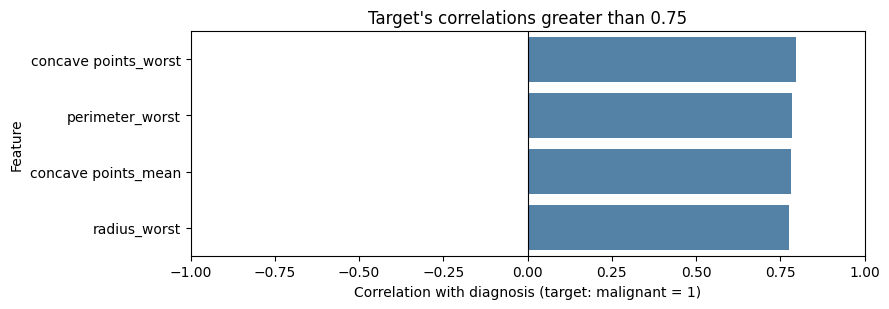

In [10]:
# I follow the instructor's threshold of 0.75 for strong target correlations.
th = 0.75
filt = np.abs(corr['target']) > th

# I do not include the target's perfect self-correlation as a predictive feature.
strong_corr = corr.loc[filt, 'target'].drop(labels=['target']).sort_values(key=abs, ascending=False)
print('Features with absolute correlation to target above', th)
print(strong_corr.to_string())

# I draw a focused horizontal bar chart to make the names and signs readable.
plt.figure(figsize=(9, max(3.2, 0.55 * len(strong_corr) + 1)))
sns.barplot(x=strong_corr.values, y=strong_corr.index, orient='h', color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation with diagnosis (target: malignant = 1)')
plt.ylabel('Feature')
plt.xlim(-1, 1)
plt.title("Target's correlations greater than " + str(th))
plt.tight_layout()
plt.show()

In [11]:
# X contains the input columns; y contains the target the models must predict.
# I keep 'id' in the course baseline because the source notebook expected 31 inputs.
# In my separate optional research notebook, I test an ID-free version.
X = df.drop(columns=['target']).copy()
y = df['target'].copy()
columns = X.columns.tolist()

# I use an 80/20 hold-out, as required in the notebook, with a fixed seed.
# Stratification preserves the class proportions in training and testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('X_train.shape:', X_train.shape)
print('X_test.shape:', X_test.shape)
print('Train class counts:', y_train.value_counts().sort_index().to_dict())
print('Test class counts:', y_test.value_counts().sort_index().to_dict())

# A sample cannot appear in both partitions; that would contaminate evaluation.
assert set(X_train.index).isdisjoint(set(X_test.index))
assert X_train.shape == (434, 31) and X_test.shape == (109, 31)

X_train.shape: (434, 31)
X_test.shape: (109, 31)
Train class counts: {0: 273, 1: 161}
Test class counts: {0: 69, 1: 40}


In [12]:
# I fit the scaler only on training features; testing data must remain unseen.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# I preserve a labeled frame for review; I avoid index mismatch with the target.
X_train_df = pd.DataFrame(X_train, columns=columns)
X_train_df['target'] = y_train

# I verify that the transformations are finite, aligned, and do not lose samples.
assert X_train_scaled.shape == X_train.shape
assert X_test_scaled.shape == X_test.shape
assert np.isfinite(X_train_scaled).all() and np.isfinite(X_test_scaled).all()
assert not X_train_df['target'].isna().any(), 'Feature/label index alignment failed.'
print('Scaling complete: fit on training set, transform on held-out test set.')

Scaling complete: fit on training set, transform on held-out test set.


# Section 4: Modeling

We will be using 3 models:<br>
1. KNN
2. SVM
3. Decision Tree <br>

We will compare how each one works.<br>
But before that, we will do some preparation first.

In [13]:
# KNN: I use k = 2 to reproduce the model choice visible in the worksheet's saved output.
knn = KNeighborsClassifier(n_neighbors=2)

# KNN is distance-based, so I train it on standardized features.
knn.fit(X_train_scaled, y_train)
print('KNN baseline:', knn)

KNN baseline: KNeighborsClassifier(n_neighbors=2)


In [14]:
# SVM: I follow the worksheet's original SVC() baseline configuration.
svc = SVC()

# I also use scaled data here because SVM is sensitive to feature magnitude.
svc.fit(X_train_scaled, y_train)
print('SVM baseline:', svc)

SVM baseline: SVC()


In [15]:
# Decision Tree: I use a reproducible baseline without post-hoc test-set tuning.
tree = DecisionTreeClassifier(random_state=SEED)

# A tree does not require feature scaling, so I fit it on the original numeric X_train.
tree.fit(X_train, y_train)
print('Decision Tree baseline:', tree)

Decision Tree baseline: DecisionTreeClassifier(random_state=42)


# Section 5: Evaluation
We want to check the performance of our model. <br> 
We want to know the accuracy of the results.

Test Score: 0.9541, Train Score: 0.9654
CM:
 [[69  0]
 [ 5 35]]


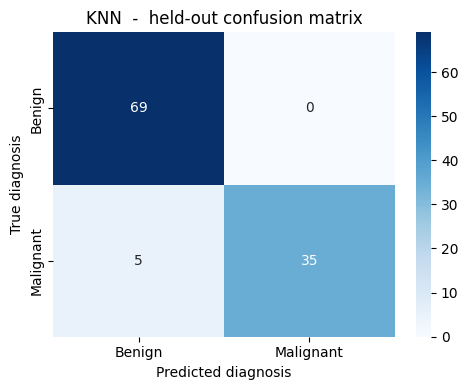

              precision    recall  f1-score   support

      Benign       0.93      1.00      0.97        69
   Malignant       1.00      0.88      0.93        40

    accuracy                           0.95       109
   macro avg       0.97      0.94      0.95       109
weighted avg       0.96      0.95      0.95       109



In [16]:
# I obtain predictions for the held-out set and fitted training observations.
y_pred_test1 = knn.predict(X_test_scaled)
y_pred_train1 = knn.predict(X_train_scaled)

# I measure both scores so overfitting is visible.
acc_test = accuracy_score(y_test, y_pred_test1)
acc_train = accuracy_score(y_train, y_pred_train1)

# I fix matrix order at 0=Benign, 1=Malignant for consistent error interpretation.
cm = confusion_matrix(y_test, y_pred_test1, labels=[0, 1])
print('Test Score: {}, Train Score: {}'.format(round(acc_test, 4), round(acc_train, 4)))
print('CM:\n', cm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.title('KNN  -  held-out confusion matrix')
plt.xlabel('Predicted diagnosis')
plt.ylabel('True diagnosis')
plt.tight_layout()
plt.show()
print(classification_report(y_test, y_pred_test1, labels=[0, 1],
                            target_names=['Benign', 'Malignant'], zero_division=0))

Test Score: 0.9908, Train Score: 0.9862
CM:
 [[69  0]
 [ 1 39]]


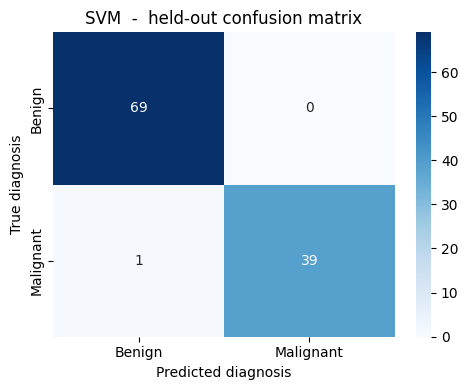

              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99        69
   Malignant       1.00      0.97      0.99        40

    accuracy                           0.99       109
   macro avg       0.99      0.99      0.99       109
weighted avg       0.99      0.99      0.99       109



In [17]:
# I evaluate SVM on the EXACT SAME held-out observations as KNN.
y_pred_test2 = svc.predict(X_test_scaled)
y_pred_train2 = svc.predict(X_train_scaled)

# I compute accuracy separately for the training and testing partitions.
acc_test2 = accuracy_score(y_test, y_pred_test2)
acc_train2 = accuracy_score(y_train, y_pred_train2)

# I report actual versus predicted categories with a consistent label order.
cm2 = confusion_matrix(y_test, y_pred_test2, labels=[0, 1])
print('Test Score: {}, Train Score: {}'.format(round(acc_test2, 4), round(acc_train2, 4)))
print('CM:\n', cm2)
plt.figure(figsize=(5, 4))
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.title('SVM  -  held-out confusion matrix')
plt.xlabel('Predicted diagnosis')
plt.ylabel('True diagnosis')
plt.tight_layout()
plt.show()
print(classification_report(y_test, y_pred_test2, labels=[0, 1],
                            target_names=['Benign', 'Malignant'], zero_division=0))

Test Score: 0.9266, Train Score: 1.0
CM:
 [[65  4]
 [ 4 36]]


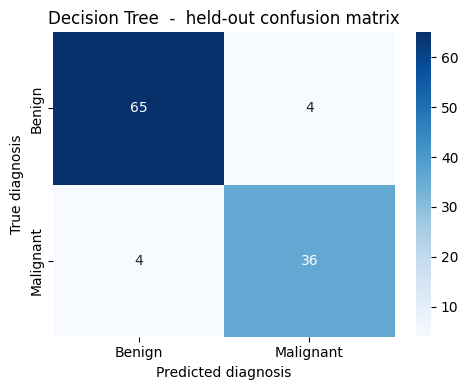

              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        69
   Malignant       0.90      0.90      0.90        40

    accuracy                           0.93       109
   macro avg       0.92      0.92      0.92       109
weighted avg       0.93      0.93      0.93       109



In [18]:
# I evaluate the Decision Tree using the same test partition as KNN and SVM.
y_pred_test3 = tree.predict(X_test)
y_pred_train3 = tree.predict(X_train)

# I check the train/test gap because an unconstrained tree may overfit.
acc_test3 = accuracy_score(y_test, y_pred_test3)
acc_train3 = accuracy_score(y_train, y_pred_train3)

# I plot errors using the same coordinate convention for all three models.
cm3 = confusion_matrix(y_test, y_pred_test3, labels=[0, 1])
print('Test Score: {}, Train Score: {}'.format(round(acc_test3, 4), round(acc_train3, 4)))
print('CM:\n', cm3)
plt.figure(figsize=(5, 4))
sns.heatmap(cm3, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.title('Decision Tree  -  held-out confusion matrix')
plt.xlabel('Predicted diagnosis')
plt.ylabel('True diagnosis')
plt.tight_layout()
plt.show()
print(classification_report(y_test, y_pred_test3, labels=[0, 1],
                            target_names=['Benign', 'Malignant'], zero_division=0))

# What is your best model?
In order to get best model, you will need to modify the parameters. <br>
Look back at the models in section 4, can you fine tune it better? <br><br>
What is your best model? How does it fare?

In [19]:
# I compare the three required baselines with the SAME 109 held-out observations.
# Accuracy is the instructor's main comparison; malignant recall and false negatives
# provide an additional check for an important error type in this use case.
from sklearn.metrics import recall_score, precision_score, f1_score

baseline_results = []
for name, prediction, train_accuracy in [
    ('KNN', y_pred_test1, acc_train),
    ('SVM', y_pred_test2, acc_train2),
    ('Decision Tree', y_pred_test3, acc_train3),
]:
    matrix = confusion_matrix(y_test, prediction, labels=[0, 1])
    baseline_results.append({
        'Model': name,
        'Test accuracy': accuracy_score(y_test, prediction),
        'Train accuracy': train_accuracy,
        'Malignant precision': precision_score(y_test, prediction, pos_label=1, zero_division=0),
        'Malignant recall': recall_score(y_test, prediction, pos_label=1, zero_division=0),
        'Malignant F1': f1_score(y_test, prediction, pos_label=1, zero_division=0),
        'False negatives': int(matrix[1, 0]),
        'False positives': int(matrix[0, 1]),
    })

baseline_table = pd.DataFrame(baseline_results)
# I follow the course's accuracy-first rule; I break ties using malignant recall.
ranked_baselines = baseline_table.sort_values(
    ['Test accuracy', 'Malignant recall', 'Malignant F1'],
    ascending=[False, False, False], kind='stable'
).reset_index(drop=True)

display(ranked_baselines.round(4))
classroom_champion = ranked_baselines.iloc[0]
print('My best REQUIRED baseline model on this reproducible split is:',
      classroom_champion['Model'])
print('Test accuracy:', f"{classroom_champion['Test accuracy']:.2%}")
print('Malignant recall:', f"{classroom_champion['Malignant recall']:.2%}")
print('False negatives:', int(classroom_champion['False negatives']))
print('Interpretation: this is an educational comparison, not a clinical validation.')
print('Improvement plan: test a predeclared hyperparameter grid on TRAINING folds only;')
print('do not keep changing the test split until a preferred score appears.')


,Model,Test accuracy,Train accuracy,Malignant precision,Malignant recall,Malignant F1,False negatives,False positives
0,SVM,0.9908,0.9862,1.0,0.975,0.9873,1,0
1,KNN,0.9541,0.9654,1.0,0.875,0.9333,5,0
2,Decision Tree,0.9266,1.0000,0.9,0.900,0.9000,4,4


My best REQUIRED baseline model on this reproducible split is: SVM
Test accuracy: 99.08%
Malignant recall: 97.50%
False negatives: 1
Interpretation: this is an educational comparison, not a clinical validation.
Improvement plan: test a predeclared hyperparameter grid on TRAINING folds only;
do not keep changing the test split until a preferred score appears.


# Section 6: Deployment
What makes a good deployment? <br>
It has to be useful and easy to use. <br>
It needs to be updated frequently and easily.<br>
Deployment can be on-premise or online.<br>

In the cell below, write down your suggestions on how you can deploy this AI model.

In [20]:
# My proposed deployment would be a small, access-controlled teaching dashboard where
# a qualified user enters the same measured features used by the trained model.
# The app would validate inputs, apply the SAME saved preprocessing steps, and display
# the predicted class together with an explanation of limitations and uncertainty.
# Each model artifact should be versioned with its training-data source and validation.
# I would monitor accuracy, sensitivity, false negatives, and distribution drift;
# any change would require fresh independent evaluation before being accepted.
# The educational WDBC classifier is NOT approved for clinical diagnosis or screening.
# A real clinical use case would need external validation, clinical oversight, privacy
# safeguards, representative data, and applicable regulatory review before deployment.

# Other Reading Materials
You can get more information through these materials: <br>
1. https://www.breastcancer.org/symptoms/understand_bc/statistics
2. https://scikit-learn.org/stable/
3. https://pandas.pydata.org/docs/reference/api/pandas.isnull.html
4. https://seaborn.pydata.org/generated/seaborn.clustermap.html
5. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
6. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
7. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
8. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
9. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html